# Práctica 2 — Sesión 1: Métricas desbalanceadas

**Dataset:** Wall-Following (continuación de la Práctica 1)  
**Entregable:** `p2_01_metricas.ipynb`

## Objetivo

Comparar un `RandomForestClassifier` con un clasificador trivial que predice siempre **0**, para determinar por qué una exactitud (*accuracy*) elevada puede ocultar errores en una clase minoritaria.

### Definición del problema binario

- **1 (positivo):** `Slight-Left-Turn`.
- **0 (negativo):** cualquier otro movimiento.

**Aviso:** se utiliza el archivo local `data/processed/dataset.parquet` creado en P1. Esta libreta no inventa resultados: las métricas se calculan al ejecutar las celdas con el dataset real.

## 1. Importar librerías

Usaremos `pandas` para datos, `scikit-learn` para separar, entrenar y evaluar, y `matplotlib` para mostrar la matriz de confusión.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42

## 2. Cargar datos y verificar las clases

Esta celda busca el `.parquet` desde la carpeta actual o desde sus carpetas superiores. Así funciona tanto si abres Jupyter desde la raíz del repositorio como desde `notebooks/`.

In [2]:
nombre_archivo = Path("data/processed/dataset.parquet")
ruta_dataset = next(
    (carpeta / nombre_archivo for carpeta in [Path.cwd(), *Path.cwd().parents]
     if (carpeta / nombre_archivo).is_file()),
    None,
)
if ruta_dataset is None:
    raise FileNotFoundError(
        "No se encontró data/processed/dataset.parquet. "
        "Abre el notebook desde el repositorio de la Práctica 1 "
        "o comprueba que ya ejecutaste la preparación de datos de P1."
    )

df = pd.read_parquet(ruta_dataset)
print(f"Archivo: {ruta_dataset}")
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
print("Columnas:", list(df.columns))
display(df.head())

Archivo: /mnt/DiscoD/U/MachineLearning/ml-practica1-zurita/data/processed/dataset.parquet
Dimensiones: 5456 filas x 26 columnas
Columnas: ['US1', 'US2', 'US3', 'US4', 'US5', 'US6', 'US7', 'US8', 'US9', 'US10', 'US11', 'US12', 'US13', 'US14', 'US15', 'US16', 'US17', 'US18', 'US19', 'US20', 'US21', 'US22', 'US23', 'US24', 'Class', 'split']


,US1,US2,US3,US4,US5,US6,US7,US8,US9,US10,...,US17,US18,US19,US20,US21,US22,US23,US24,Class,split
0,-0.555806,-0.325067,-0.535488,-0.442497,-0.491462,-0.199362,0.580033,1.188018,0.686723,1.217881,...,-0.156981,0.032680,0.080838,0.606897,0.209977,-0.150837,-0.336249,-0.605744,Move-Forward,train
1,-0.216460,1.578024,2.395991,0.148354,0.046320,-0.155168,-0.255974,-0.269598,0.686723,-0.868642,...,-0.383396,-0.179739,-0.125749,13.189272,0.622970,2.986270,0.045999,-0.177546,Sharp-Right-Turn,train
2,-0.961669,-1.057612,-1.266108,0.512185,0.108342,0.125215,-0.094272,0.286807,-0.341955,-0.192187,...,-0.588679,-0.683007,-0.646707,-0.640613,-0.697216,-0.429942,-0.784580,-1.061358,Slight-Right-Turn,train
3,0.104848,-0.360168,-0.498670,-0.417700,0.911874,0.253867,-0.011129,0.653282,0.323513,1.217881,...,-0.419623,-0.614379,-0.604790,-0.597701,-0.254060,2.986270,0.137998,0.191906,Slight-Right-Turn,train
4,-0.496054,-0.754674,-0.451217,-0.400171,0.911874,-0.553891,0.580033,1.196941,0.686723,1.217881,...,-0.320000,-0.258170,-0.221557,0.196169,0.395592,0.105699,-0.231293,-0.528721,Move-Forward,train


In [3]:
if "Class" not in df.columns:
    raise KeyError("No existe la columna 'Class'. Revisa el dataset procesado de P1.")

clases = df["Class"].astype(str).str.strip()
frecuencias = clases.value_counts()
porcentajes = clases.value_counts(normalize=True).mul(100).round(2)
resumen_clases = pd.DataFrame({
    "Cantidad": frecuencias,
    "Porcentaje (%)": porcentajes,
})
display(resumen_clases)

,Cantidad,Porcentaje (%)
Class,,
Move-Forward,2205,40.41
Sharp-Right-Turn,2097,38.43
Slight-Right-Turn,826,15.14
Slight-Left-Turn,328,6.01


## 3. Convertir el problema a clasificación binaria

Seleccionamos `Slight-Left-Turn`, que en el conjunto original es la clase menos frecuente. Esta celda **verifica** si continúa siendo la minoritaria en el archivo que estás usando.

Las columnas `US1`–`US24` son las variables predictoras y `Class` es la etiqueta original.

In [4]:
CLASE_POSITIVA = "Slight-Left-Turn"
if CLASE_POSITIVA not in frecuencias.index:
    raise ValueError(
        f"No se encontró {CLASE_POSITIVA!r}. Clases disponibles: {list(frecuencias.index)}"
    )

clase_menor = frecuencias.idxmin()
if clase_menor != CLASE_POSITIVA:
    print(f"ATENCIÓN: la clase menos frecuente en este archivo es {clase_menor!r}.")

columnas_sensores = [f"US{i}" for i in range(1, 25)]
faltantes = [c for c in columnas_sensores if c not in df.columns]
if faltantes:
    raise KeyError(f"Faltan columnas de sensores: {faltantes}")

X = df[columnas_sensores].apply(pd.to_numeric, errors="raise")
y = (clases == CLASE_POSITIVA).astype(int)

if X.isna().any().any():
    raise ValueError("Hay valores ausentes en US1–US24: revisa la limpieza realizada en P1.")

print("Distribución binaria (0 = otros, 1 = Slight-Left-Turn):")
display(pd.DataFrame({"Cantidad": y.value_counts().sort_index(),
                      "Porcentaje (%)": y.value_counts(normalize=True).sort_index().mul(100).round(2)}))

Distribución binaria (0 = otros, 1 = Slight-Left-Turn):


,Cantidad,Porcentaje (%)
Class,,
0,5128,93.99
1,328,6.01


## 4. Dividir en entrenamiento y prueba (estratificado)

**Estratificado** significa mantener aproximadamente la misma proporción de clases en ambos subconjuntos.

Separación: **80 % entrenamiento / 20 % prueba**, con semilla `42` para reproducibilidad.

> Para evitar fugas de información (*data leakage*), no ajustes escaladores ni hiperparámetros con el conjunto de prueba. Random Forest no necesita escalado adicional para esta actividad.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Entrenamiento: {len(y_train)} muestras; positivas: {y_train.sum()} ({y_train.mean():.2%})")
print(f"Prueba:        {len(y_test)} muestras; positivas: {y_test.sum()} ({y_test.mean():.2%})")

Entrenamiento: 4364 muestras; positivas: 262 (6.00%)
Prueba:        1092 muestras; positivas: 66 (6.04%)


## 5. Entrenar Random Forest y el modelo trivial

- **Random Forest:** aprende patrones a partir de los sensores.
- **DummyClassifier (constant=0):** jamás detecta la clase positiva. Puede aparentar buen *accuracy* porque la mayoría de ejemplos pertenecen a la clase 0.

Ambos se evalúan sobre **el mismo conjunto de prueba**.

In [6]:
modelo_rf = RandomForestClassifier(
    n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
)
modelo_rf.fit(X_train, y_train)

modelo_trivial = DummyClassifier(strategy="constant", constant=0)
modelo_trivial.fit(X_train, y_train)

pred_rf = modelo_rf.predict(X_test)
pred_trivial = modelo_trivial.predict(X_test)
print("Modelos entrenados. Predicciones generadas sobre el conjunto de prueba.")

Modelos entrenados. Predicciones generadas sobre el conjunto de prueba.


## 6. Métricas y matriz de confusión

Interpretación para la clase **1**:

- **TP:** era `Slight-Left-Turn` y se predijo 1.
- **TN:** era otra clase y se predijo 0.
- **FP:** era otra clase, pero se predijo 1.
- **FN:** era `Slight-Left-Turn`, pero se predijo 0.

Fórmulas principales:

\[
\mathrm{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}
\]
\[
\mathrm{Precision}=\frac{TP}{TP+FP},\quad
\mathrm{Recall}=\frac{TP}{TP+FN},\quad
F_1=\frac{2\cdot\mathrm{Precision}\cdot\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}
\]

`zero_division=0` evita advertencias cuando el clasificador trivial nunca predice positivos.

In [7]:
def evaluar_modelo(nombre, verdad, prediccion):
    """Calcula métricas binarias y extrae TN, FP, FN, TP."""
    tn, fp, fn, tp = confusion_matrix(verdad, prediccion, labels=[0, 1]).ravel()
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(verdad, prediccion),
        "Precision": precision_score(verdad, prediccion, zero_division=0),
        "Recall": recall_score(verdad, prediccion, zero_division=0),
        "F1": f1_score(verdad, prediccion, zero_division=0),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

resultados = pd.DataFrame([
    evaluar_modelo("Random Forest", y_test, pred_rf),
    evaluar_modelo("Siempre 0", y_test, pred_trivial),
]).set_index("Modelo")

display(resultados.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}",
    "Recall": "{:.4f}", "F1": "{:.4f}",
}))

,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
Modelo,,,,,,,,
Random Forest,0.9936,1.0000,0.8939,0.9440,1026,0,7,59
Siempre 0,0.9396,0.0000,0.0000,0.0000,1026,0,66,0


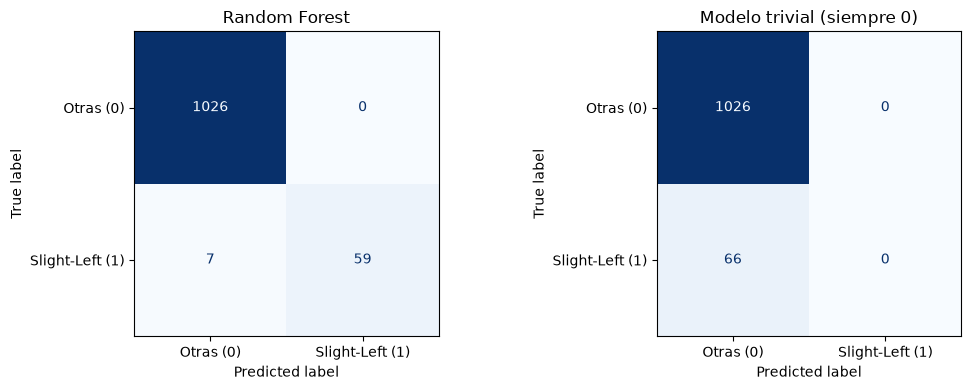

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, prediccion, nombre in zip(
    axes,
    [pred_rf, pred_trivial],
    ["Random Forest", "Modelo trivial (siempre 0)"],
):
    ConfusionMatrixDisplay.from_predictions(
        y_test, prediccion, labels=[0, 1], display_labels=["Otras (0)", "Slight-Left (1)"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

## 7. Conclusión de tres líneas para el entregable

La siguiente celda genera una conclusión **a partir de los resultados reales**. Léela, comprueba que estás de acuerdo con la interpretación y úsala en el reporte.

In [9]:
rf = resultados.loc["Random Forest"]
trivial = resultados.loc["Siempre 0"]
print(
    f"1. La clase Slight-Left-Turn representa el {y.mean():.2%} del dataset, "
    "por lo que el problema binario está desbalanceado.\n"
    f"2. El modelo trivial obtiene accuracy={trivial['Accuracy']:.3f}, "
    f"pero recall={trivial['Recall']:.3f} y F1={trivial['F1']:.3f}: "
    "no reconoce ningún caso positivo.\n"
    f"3. Random Forest obtiene accuracy={rf['Accuracy']:.3f}, "
    f"recall={rf['Recall']:.3f}, F1={rf['F1']:.3f}; "
    f"comete {int(rf['FN'])} falsos negativos frente a "
    f"{int(trivial['FN'])} del trivial."
)

1. La clase Slight-Left-Turn representa el 6.01% del dataset, por lo que el problema binario está desbalanceado.
2. El modelo trivial obtiene accuracy=0.940, pero recall=0.000 y F1=0.000: no reconoce ningún caso positivo.
3. Random Forest obtiene accuracy=0.994, recall=0.894, F1=0.944; comete 7 falsos negativos frente a 66 del trivial.


El modelo Random Forest alcanzó un accuracy del 99,36 %, un F1 del 94,40 % y un recall del 89,39 % para la clase minoritaria.

El modelo trivial obtuvo un accuracy del 93,96 %, pero no identificó ningún movimiento minoritario, demostrando las limitaciones del accuracy ante datos desbalanceados.

Random Forest presenta un rendimiento significativamente mejor en esta evaluación, aunque sus siete falsos negativos representan una oportunidad de mejora.